311 call data Analysis

In [271]:
#imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [272]:
#path to retrieve 311 data set
data_path = "C:/Users/Nathan/Desktop/Py_2/Final Project/pgh_311_data.csv"
pgh_311_df = pd.read_csv(data_path)

In [273]:
#basic dataset description
display(pgh_311_df.shape)
display(pgh_311_df.columns)
display(pgh_311_df.isna().sum())
display(pgh_311_df.dtypes)
display(pgh_311_df.describe())

(815417, 29)

Index(['_id', 'group_id', 'num_requests', 'parent_closed', 'status_name',
       'status_code', 'dept', 'request_type_name', 'request_type_id',
       'create_date_et', 'create_date_utc', 'last_action_et',
       'last_action_utc', 'closed_date_et', 'closed_date_utc', 'origin',
       'street', 'cross_street', 'street_id', 'cross_street_id', 'city',
       'neighborhood', 'census_tract', 'council_district', 'ward',
       'police_zone', 'latitude', 'longitude', 'geo_accuracy'],
      dtype='str')

_id                       0
group_id                  0
num_requests              0
parent_closed             0
status_name               0
status_code               0
dept                   4223
request_type_name         0
request_type_id           0
create_date_et            0
create_date_utc           0
last_action_et            0
last_action_utc           0
closed_date_et        93338
closed_date_utc       93338
origin                    0
street               315184
cross_street         712948
street_id            308644
cross_street_id      308644
city                      0
neighborhood          37372
census_tract         228342
council_district      35922
ward                  37203
police_zone           37466
latitude              31408
longitude             31408
geo_accuracy              0
dtype: int64

_id                    int64
group_id               int64
num_requests           int64
parent_closed            str
status_name              str
status_code            int64
dept                     str
request_type_name        str
request_type_id        int64
create_date_et           str
create_date_utc          str
last_action_et           str
last_action_utc          str
closed_date_et           str
closed_date_utc          str
origin                   str
street                   str
cross_street             str
street_id            float64
cross_street_id      float64
city                     str
neighborhood             str
census_tract         float64
council_district     float64
ward                 float64
police_zone          float64
latitude             float64
longitude            float64
geo_accuracy             str
dtype: object

,_id,group_id,num_requests,status_code,request_type_id,street_id,cross_street_id,census_tract,council_district,ward,police_zone,latitude,longitude
count,815417.000000,815417.000000,815417.000000,815417.000000,815417.000000,506773.000000,506773.000000,5.870750e+05,779495.000000,778214.000000,777951.000000,784009.000000,784009.000000
mean,407713.887753,465551.015877,1.038919,1.062843,25492.850015,2848.500996,600.844104,4.200323e+10,4.768956,16.327310,3.552653,40.260594,-79.618239
std,235399.013746,269724.662407,0.419785,0.538681,96079.987098,1900.613054,1565.535899,1.859526e+05,2.539430,8.090777,1.598986,2.692305,5.324147
min,1.000000,836.000000,1.000000,0.000000,272.000000,0.000000,0.000000,4.200301e+10,1.000000,0.000000,1.000000,0.000000,-87.621300
25%,203855.000000,230072.000000,1.000000,1.000000,415.000000,1262.000000,0.000000,4.200311e+10,3.000000,10.000000,2.000000,40.422472,-80.008406
50%,407709.000000,463899.000000,1.000000,1.000000,494.000000,2783.000000,0.000000,4.200318e+10,5.000000,16.000000,4.000000,40.443250,-79.978139
75%,611563.000000,704989.000000,1.000000,1.000000,831.000000,4194.000000,0.000000,4.200328e+10,7.000000,22.000000,5.000000,40.461256,-79.936879
max,815728.000000,926123.000000,175.000000,4.000000,887310.000000,12562.000000,12561.000000,4.200398e+10,9.000000,32.000000,6.000000,41.885800,0.000000


In [274]:
#request mode via "origin" variable:

origin_pcts = (pgh_311_df["origin"].value_counts(normalize=True) * 100).round(2).astype(str) + "%"
origin_counts = pgh_311_df["origin"].value_counts()
origin_sum_df = pd.concat([origin_counts, origin_pcts], axis=1).reset_index().rename(columns={"proportion":"percent"})
display(origin_sum_df.shape)
display(origin_sum_df)

(10, 3)

,origin,count,percent
0,Call Center,482584,59.18%
1,Website,200158,24.55%
2,Control Panel,56489,6.93%
3,Report2Gov iOS,30187,3.7%
4,Twitter,12893,1.58%
5,Report2Gov Android,10633,1.3%
6,Report2Gov Website,9660,1.18%
7,Email,8374,1.03%
8,Text Message,4434,0.54%
9,QAlert Mobile iOS,5,0.0%


In [275]:
#date variables converted to date/time objects
pgh_311_df["create_date_et"] = pd.to_datetime(pgh_311_df["create_date_et"])
pgh_311_df["closed_date_et"] = pd.to_datetime(pgh_311_df["closed_date_et"])
pgh_311_df["last_action_et"] = pd.to_datetime(pgh_311_df["last_action_et"])


#first and last dates shown in the dataset
display(pgh_311_df[["create_date_et", "closed_date_et", "last_action_et"]].min())
display(pgh_311_df[["create_date_et", "closed_date_et", "last_action_et"]].max())


create_date_et   2015-04-20 07:37:00
closed_date_et   2015-04-20 13:20:00
last_action_et   2015-04-20 13:20:00
dtype: datetime64[us]

create_date_et   2025-03-10 10:28:00
closed_date_et   2025-03-24 06:14:00
last_action_et   2025-03-24 06:14:00
dtype: datetime64[us]

In [276]:
#time_to_close will equal difference in time between when 311 request was made and when it was closed, or nan if one date is missing
#the following shows 722079 out of 815417 cases were closed at some point
pgh_311_df["time_to_close"] = pgh_311_df["closed_date_et"] - pgh_311_df["create_date_et"]
display(pgh_311_df["time_to_close"].isna().value_counts())

#setting discrete time period for data visualization purposes
pgh_311_df["days_to_close"] = pgh_311_df["time_to_close"].dt.days

#time to action includes all cases in dataset
pgh_311_df["time_to_action"] = pgh_311_df["last_action_et"] - pgh_311_df["create_date_et"]
display(pgh_311_df["time_to_action"].isna().value_counts())

print(f"Average time to close is {pgh_311_df["time_to_close"].mean()} and the median time to close is {pgh_311_df["time_to_close"].median()}")
pgh_311_df["days_to_close"].describe()





time_to_close
False    722079
True      93338
Name: count, dtype: int64

time_to_action
False    815417
Name: count, dtype: int64

Average time to close is 87 days 17:31:02.914168 and the median time to close is 7 days 22:29:00


count    722079.000000
mean         87.229392
std         249.156507
min           0.000000
25%           1.000000
50%           7.000000
75%          43.000000
max        3529.000000
Name: days_to_close, dtype: float64

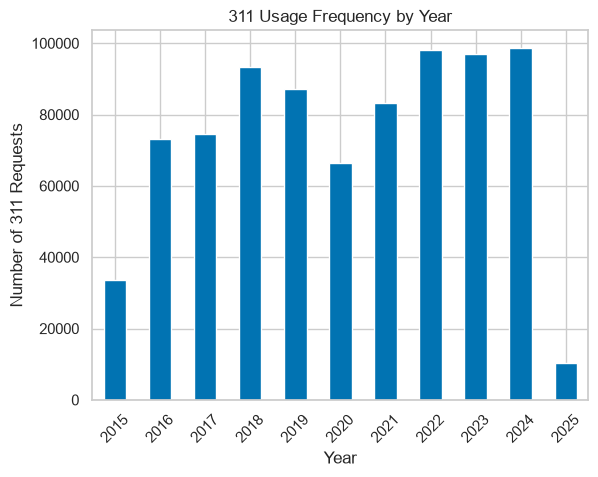

In [277]:
#univariate analysis of create_date
import matplotlib.dates as mdates
#311 use plotted over month in pseudo-histogram
pgh_311_df["create_date_et"] = pd.to_datetime(pgh_311_df["create_date_et"])

pgh_311_df["create_date_et"].dt.year.value_counts().sort_index().plot(
    kind="bar",
    title="311 Usage Frequency by Year",
    xlabel="Year",
    ylabel="Number of 311 Requests",
    rot=45
)
plt.show()


count    722079.000000
mean         87.229392
std         249.156507
min           0.000000
25%           1.000000
50%           7.000000
75%          43.000000
max        3529.000000
Name: days_to_close, dtype: float64

days_to_close above 106.0 are outliers


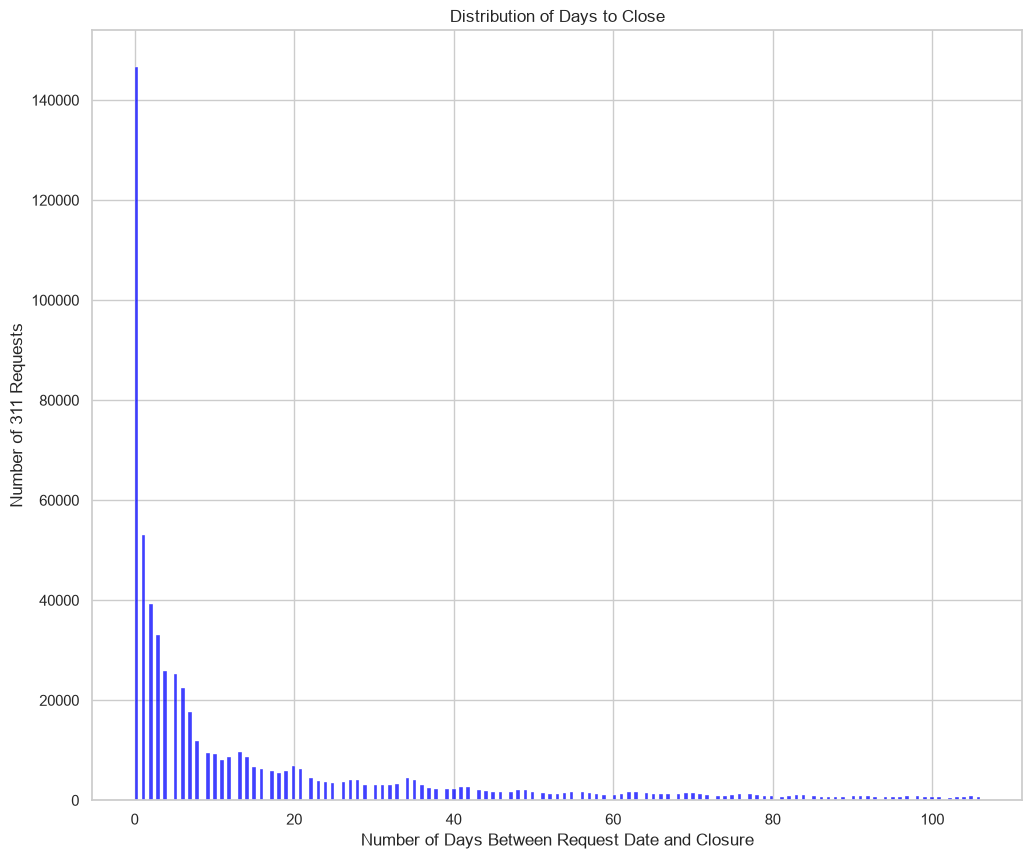

In [278]:
#univariate analysis of days_to_close

display(pgh_311_df["days_to_close"].describe())

#set bounds to filter out days_to_close outliers
q1 = pgh_311_df["days_to_close"].quantile(0.25)
q3 = pgh_311_df["days_to_close"].quantile(0.75)
iqr =  q3 - q1
upper_bound = q3 + (1.5 * iqr)
lower_bound = q1 - (1.5 * iqr)

print(f"days_to_close above {upper_bound} are outliers")


days_outlier_filter_df = pgh_311_df[(pgh_311_df["days_to_close"] <= upper_bound) & (pgh_311_df["days_to_close"] > lower_bound)]


#histogram of days_to_close, showing extremely right_skewed data
#without an xlimit, the maximum is 3,529
plt.figure(figsize=(12, 10))
sns.histplot(data=days_outlier_filter_df, x="days_to_close", color="blue")
plt.title("Distribution of Days to Close")
plt.xlabel("Number of Days Between Request Date and Closure")
plt.ylabel("Number of 311 Requests")
plt.show()


col_0,create_year,in_progress,on_hold,open
0,2015,19,0,0
1,2016,6831,5,215
2,2017,6192,3,1785
3,2018,4549,16,2219
4,2019,4941,26,2633
5,2020,2880,43,3180
6,2021,4447,44,6080
7,2022,3964,93,6696
8,2023,5094,134,8192
9,2024,7203,109,12340


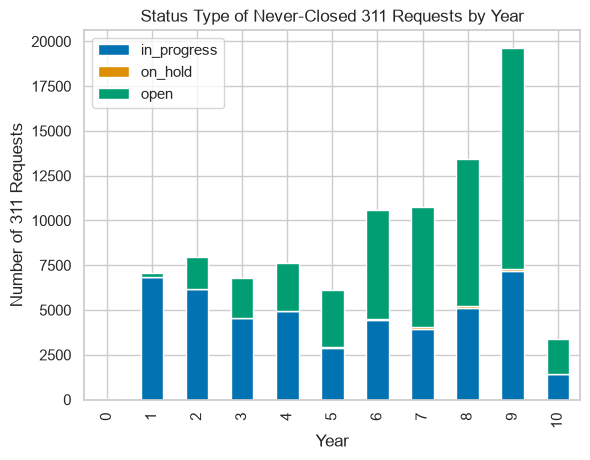

,create_date_et,ct_requests
0,2015,19
1,2016,7051
2,2017,7980
3,2018,6784
4,2019,7600
5,2020,6103
6,2021,10571
7,2022,10753
8,2023,13420
9,2024,19652


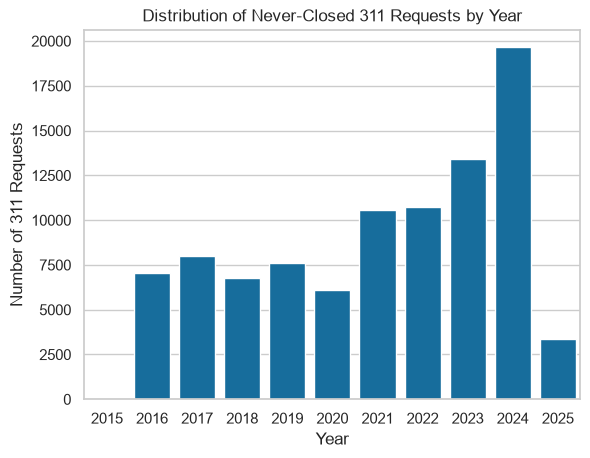

In [289]:
#subset of data that indicates no closing times

#the following chart shows the number of opened 311 requests that were not closed within the time period of this dataset
never_closed_df = pgh_311_df[pgh_311_df["closed_date_et"].isna()]

#pgh_311_df["never_closed"] = pgh_311_df["closed_date_et"].isna()

#create int variable describing year for visualizations
pgh_311_df["create_year"] = pgh_311_df["create_date_et"].dt.year



year_cat = pd.Categorical(never_closed_df["create_year"])
status_cat = pd.Categorical(never_closed_df["status_name"])
status_year_df = pd.crosstab(index=year_cat, columns=status_cat).reset_index().rename(columns={"row_0":"create_year", "in progress":"in_progress", "on hold":"on_hold"})
display(status_year_df)

status_year_df.plot(kind="bar", stacked=True)
plt.title("Status Type of Never-Closed 311 Requests by Year")
plt.xlabel("Year")
plt.ylabel("Number of 311 Requests")
plt.legend()
plt.show()

#table of cases never closed by year
plot_year_data = (never_closed_df["create_date_et"]
    .dt.year.value_counts()
    .sort_index()
    .reset_index(name="ct_requests"))
display(plot_year_data)

#barplot of data above
sns.barplot(data=plot_year_data, x="create_date_et", y="ct_requests")
plt.title("Distribution of Never-Closed 311 Requests by Year")
plt.xlabel("Year")
plt.ylabel("Number of 311 Requests")
plt.show()




In [281]:
#univariate analysis of request_type_name, standardized categories used by the city for each 311 call to use as a descriptor

#dropping request types that contain "DO NOT USE"
pgh_311_df = pgh_311_df[pgh_311_df["request_type_name"].str.contains("(DO NOT USE)") == False]


#number of request types
display(pgh_311_df["request_type_name"].nunique())

#create table to summarize request_type_name across the dataset
request_type_pcts = (pgh_311_df["request_type_name"].value_counts(normalize=True) * 100).round(2).astype("string") + "%"
request_type_cts = pgh_311_df["request_type_name"].value_counts()
request_type_sum_df = pd.concat([request_type_cts, request_type_pcts], axis=1).reset_index().rename(columns={"proportion":"percent"})

display(request_type_sum_df.shape)

#ten most and least common request types
display(request_type_sum_df.head(10))
display(request_type_sum_df.tail(10))

#top 25 311 request types in table form
display(pgh_311_df["request_type_name"].value_counts().nlargest(25).reset_index())


C:\Users\Nathan\AppData\Local\Temp\ipykernel_14652\487810780.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  pgh_311_df = pgh_311_df[pgh_311_df["request_type_name"].str.contains("(DO NOT USE)") == False]


327

(327, 3)

,request_type_name,count,percent
0,Weeds/Debris,77513,9.52%
1,Potholes,67502,8.29%
2,Missed Refuse Pick Up,42185,5.18%
3,Snow/Ice removal,34942,4.29%
4,Building Maintenance,28863,3.54%
5,Refuse Violations,26598,3.27%
6,Abandoned Vehicle (parked on street),23768,2.92%
7,Illegal Parking,21289,2.61%
8,Missed Recycling Pick Up,17987,2.21%
9,Street Light - Repair,17903,2.2%


,request_type_name,count,percent
317,EMT,7,0.0%
318,KNOWLEDGE BASE ARTICLES,7,0.0%
319,Improvements,6,0.0%
320,Land Bank,5,0.0%
321,Bicycle/Pedestrian/Trail - Network Improvements,3,0.0%
322,Catch Basins,3,0.0%
323,Billing,3,0.0%
324,Permits,3,0.0%
325,Roadway Obstructions,1,0.0%
326,Amenities,1,0.0%


,request_type_name,count
0,Weeds/Debris,77513
1,Potholes,67502
2,Missed Refuse Pick Up,42185
3,Snow/Ice removal,34942
4,Building Maintenance,28863
5,Refuse Violations,26598
6,Abandoned Vehicle (parked on street),23768
7,Illegal Parking,21289
8,Missed Recycling Pick Up,17987
9,Street Light - Repair,17903


,request_type_name,count,days_to_close
324,Weeds/Debris,77513,19.0
217,Potholes,67502,10.0
165,Missed Refuse Pick Up,42185,2.0
267,Snow/Ice removal,34942,1.0
32,Building Maintenance,28863,28.0
...,...,...,...
207,Permits,3,258.0
20,Bicycle/Pedestrian/Trail - Network Improvements,3,936.0
44,Catch Basins,3,75.0
8,Amenities,1,527.0


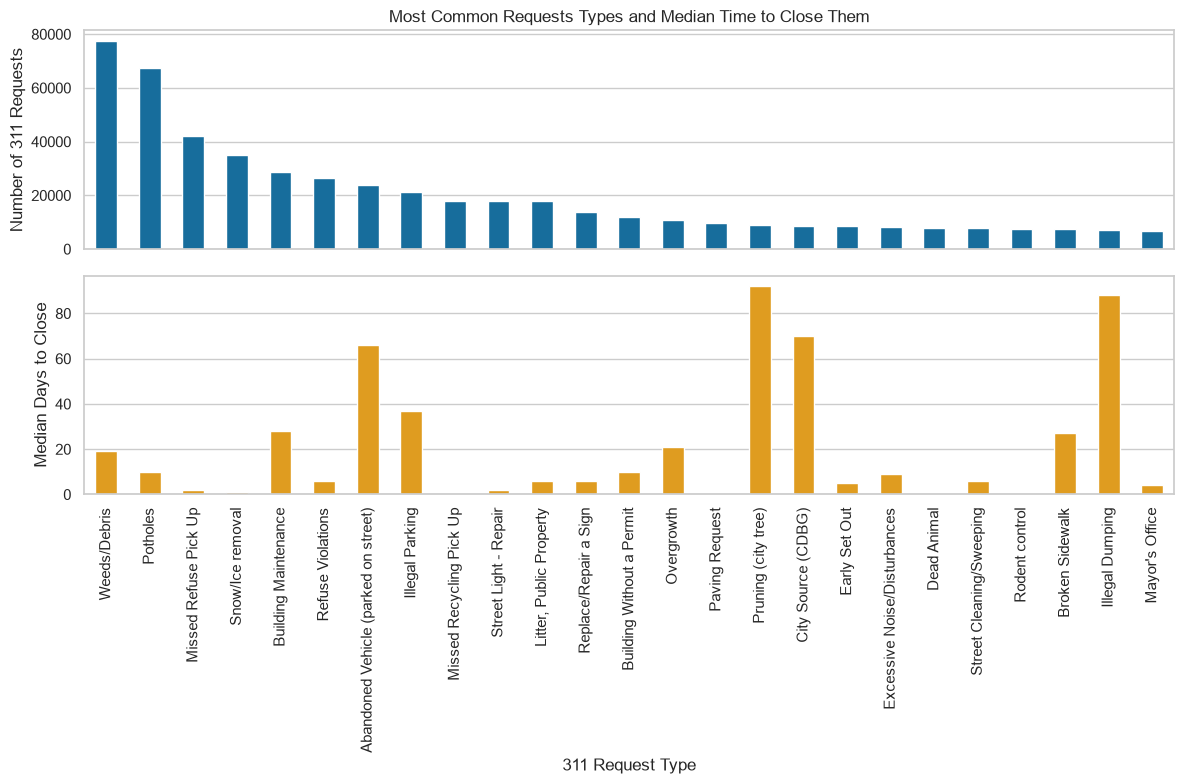

Index(['days_to_close', '911 Performance', 'ADA Ramp, Installation',
       'Abandoned Vehicle', 'Abandoned Vehicle (parked on street)',
       'Accessibility Construction Issue', 'Accessible Parking Application',
       'Accessible Parking Signs, Removal', 'Alarm Permit', 'Amenities',
       ...
       'Utility Pole', 'Vacant Building', 'Vacant Lot', 'Water Main Break',
       'Water Pressure', 'Water Runoff in ROW', 'Water/Drinking Fountains',
       'Weeds/Debris', 'Wires', 'Zoning Issue'],
      dtype='str', length=328)

c:\Users\Nathan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Nathan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,request_type_name,corr_coeff_wrt_days_to_close
0,Sidewalk/Curb/ADA Ramp Maintenance,0.151204
1,Dead Tree (3TB),0.087712
2,Repair City Steps,0.087234
3,Blocked or Closed Sidewalks,0.085644
4,Homeless,0.081577
5,Illegal Parking,0.079590
6,Traffic Enforcement,0.074510
7,Pruning (city tree),0.068901
8,Patrol,0.067842
9,Speeding,0.062433


In [290]:
#bivariate analysis of time_to_close, request_type_name

#create summary table for the count and median
top_25_reqs = pgh_311_df.groupby("request_type_name").size()
top_25_req_medians = pgh_311_df.groupby("request_type_name")["days_to_close"].median()
top_25_req_means = pgh_311_df.groupby("request_type_name")["days_to_close"].mean()
request_sum_df = pd.concat((top_25_reqs, top_25_req_medians), axis=1).reset_index().rename(columns={0:"count"}).sort_values(by="count", ascending=False)
display(request_sum_df)

#two plots in vertical formation showing the quantity of 311 requests and the median days to close for the top 25 requests
sns.set_theme(style="whitegrid", palette="colorblind")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

sns.barplot(data=request_sum_df.head(25), x="request_type_name", y="count", width=0.5, ax=axes[0])
axes[0].set_title("Most Common Requests Types and Median Time to Close Them")
axes[0].set_xticklabels("")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of 311 Requests")
plt.xlabel("")

sns.barplot(data=request_sum_df.head(25), x="request_type_name", y="days_to_close", width = 0.5, ax=axes[1], color="Orange")
axes[1].set_title("")
axes[1].tick_params(axis='x', labelrotation=90)
axes[1].set_xlabel("311 Request Type")
axes[1].set_ylabel("Median Days to Close")
plt.tight_layout()
plt.show()



#generate dummy variables for each 
request_type_dummies = pd.get_dummies(pgh_311_df["request_type_name"])

#create a dataframe containing only dummy variables and days_to_close as the dependent var for correlation
request_corr_df = pd.concat([pgh_311_df[["days_to_close"]], request_type_dummies], axis=1)

display(request_corr_df.columns)
#pairwise correlation between days_to_close and dummies for each request_type_name
corr_series = request_corr_df.corrwith(request_corr_df["days_to_close"])

#removes correlation between days_to_close and days_to_close
corr_series = corr_series.loc[corr_series < 1]

display(corr_series.sort_values(ascending=False).nlargest(25).reset_index().rename(columns={"index":"request_type_name", 0:"corr_coeff_wrt_days_to_close"}))




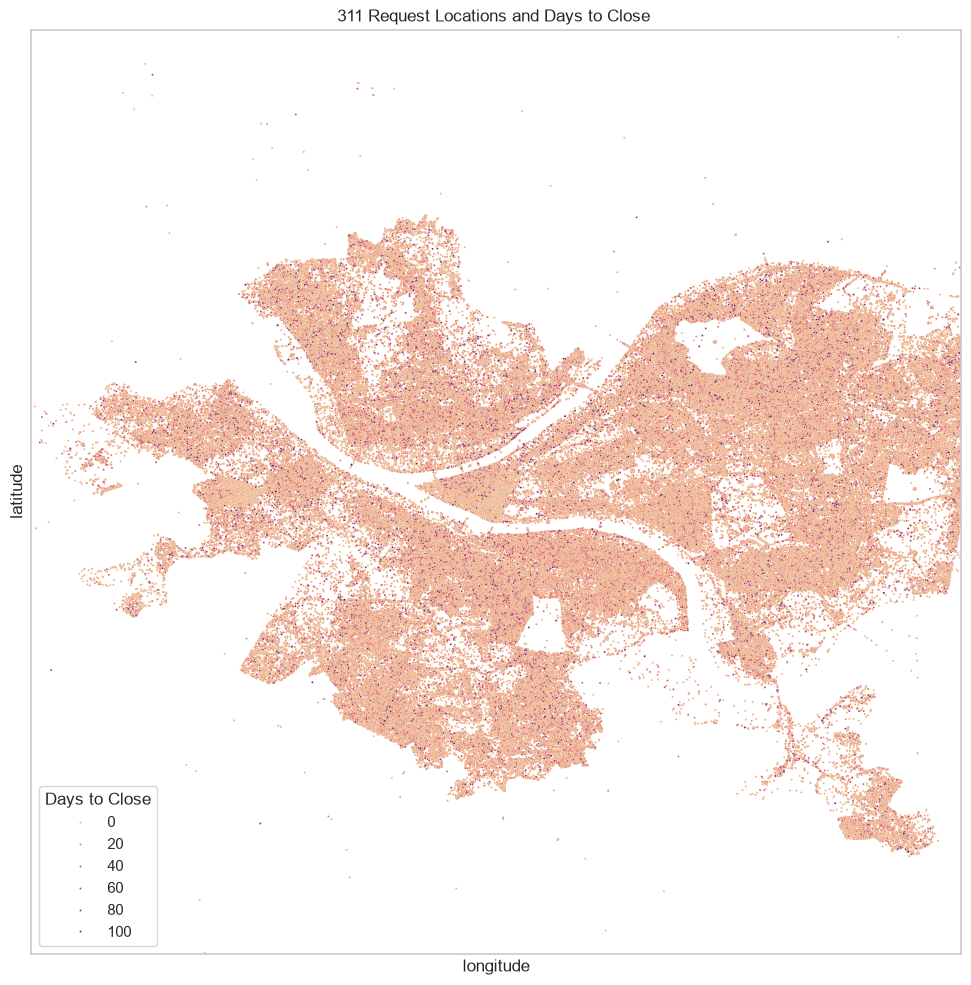

In [ ]:
#scatterplot of 311 requests with hue to show how long the 311 requests were open

#set latitude/longitude bounds
lat = 40.4406
lon = -79.9959
interval = 0.1


cmap = sns.color_palette("flare", as_cmap=True)
plt.figure(figsize=(12, 12))
sns.scatterplot(data=days_outlier_filter_df, x="longitude", y="latitude", hue="days_to_close", s=2, palette=cmap)
plt.title("311 Request Locations and Days to Close ")
plt.xlim(lon - interval, lon + interval)
plt.ylim(lat - interval, lat + interval)
plt.xticks(ticks=[], labels="")
plt.yticks(ticks=[], labels="")
plt.legend(title="Days to Close", loc="lower left")
plt.show()
